# 01 – Cài đặt và dữ liệu
**CNN cho nhận diện cảm xúc khuôn mặt (FER2013) – PyTorch** · Topics in Deep Learning  
Trần Nguyễn Minh Tiến (3123580052) · Nguyễn Gia Huy (3123580016)  


In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os
PROJECT = "/content/drive/MyDrive/FER2013_PyTorch"
os.makedirs(PROJECT, exist_ok=True)
print(os.listdir(PROJECT))

Mounted at /content/drive
['__pycache__', 'runs', 'common.py', 'data.py']


## 1.1 Ghi module dùng chung `common.py`

In [2]:
%%writefile /content/drive/MyDrive/FER2013_PyTorch/common.py
"""Cấu hình + import dùng chung (Colab)."""
import os, csv, json, time, random, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from PIL import Image
from sklearn.metrics import confusion_matrix, f1_score

PROJECT = "/content/drive/MyDrive/FER2013_PyTorch"
DATA_CSV = PROJECT + "/fer2013.csv"
RUNS_DIR = Path(PROJECT) / "runs"
RUNS_DIR.mkdir(parents=True, exist_ok=True)
CLASSES = ["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"]
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

Overwriting /content/drive/MyDrive/FER2013_PyTorch/common.py


## 1.2 Ghi module dữ liệu `data.py`
Nhãn: 0=Angry, 1=Disgust, 2=Fear, 3=Happy, 4=Sad, 5=Surprise, 6=Neutral. Augmentation: `none` | `basic` (lật, xoay ±10°, dịch 10%, zoom) | `strong`.

In [3]:
%%writefile /content/drive/MyDrive/FER2013_PyTorch/data.py
"""Dữ liệu FER2013 (Tiến – 3123580052). Tự tải bằng kagglehub nếu chưa có cache."""
from common import *

USAGE = {"Training": "train", "PublicTest": "valid", "PrivateTest": "test"}
COMPETITION = "challenges-in-representation-learning-facial-expression-recognition-challenge"
CACHE_NPZ = PROJECT + "/fer2013_cache.npz"
_CACHE = {}

def _is_fer_csv(path):
    """CSV hợp lệ phải có 3 cột emotion, pixels, Usage (train.csv/test.csv của cuộc thi KHÔNG đủ)."""
    try:
        with open(path, newline="") as f:
            h = [c.strip().lower() for c in next(csv.reader(f))]
        return {"emotion", "pixels", "usage"} <= set(h)
    except Exception:
        return False

def _find_csv(root):
    """Tìm fer2013.csv / icml_face_data.csv trong root; tự giải nén .tar.gz/.zip nếu cần."""
    import glob, shutil, tarfile
    ext = PROJECT + "/_extract"
    for f in glob.glob(root + "/**/*", recursive=True):
        low = os.path.basename(f).lower()
        if not os.path.isfile(f) or not (("fer2013" in low) or ("icml" in low)): continue
        try:
            if low.endswith((".tar.gz", ".tgz")):
                tarfile.open(f).extractall(ext)
            elif low.endswith(".zip"):
                shutil.unpack_archive(f, ext)
        except Exception as e:
            print("Không giải nén được", f, e)
    cands = [p for pat in (root, ext) for p in glob.glob(pat + "/**/*.csv", recursive=True)]
    cands.sort(key=lambda p: (0 if "fer2013" in os.path.basename(p).lower() else 1))
    for p in cands:
        if _is_fer_csv(p): return p
    raise FileNotFoundError("Không thấy CSV có cột emotion,pixels,Usage trong " + root +
                            ". Các CSV tìm được: " + str([os.path.basename(p) for p in cands]))

HF_URL = "https://huggingface.co/datasets/JimmyUnleashed/FER-2013/resolve/main/fer2013.tar.gz"
HF_MD5 = "ca95d94fe42f6ce65aaae694d18c628a"

def _download_hf():
    """Mirror công khai trên Hugging Face (không cần tài khoản Kaggle)."""
    import urllib.request, hashlib
    d = PROJECT + "/_dl"; os.makedirs(d, exist_ok=True)
    dst = d + "/fer2013.tar.gz"
    if not os.path.exists(dst):
        print("Tải fer2013.tar.gz từ Hugging Face ...")
        urllib.request.urlretrieve(HF_URL, dst)
    md5 = hashlib.md5(open(dst, "rb").read()).hexdigest()
    print("md5 =", md5, "(khớp tham chiếu)" if md5 == HF_MD5 else "(KHÁC tham chiếu - kiểm tra số lượng ảnh bên dưới)")
    return _find_csv(d)

def download_fer_csv():
    """Thử Kaggle trước (đúng nguồn của đề bài); nếu 403/chưa đăng nhập thì dùng mirror Hugging Face."""
    try:
        import kagglehub
        path = kagglehub.competition_download(COMPETITION)
        print("Path to competition files:", path)
        return _find_csv(path)
    except Exception as e:
        print("Kaggle không tải được (" + type(e).__name__ + "). Chuyển sang mirror Hugging Face.")
        return _download_hf()

def _parse_csv(csv_path):
    xs = {k: [] for k in USAGE.values()}; ys = {k: [] for k in USAGE.values()}
    with open(csv_path, newline="") as f:
        rd = csv.reader(f)
        h = [c.strip().lower() for c in next(rd)]
        ie, ip, iu = h.index("emotion"), h.index("pixels"), h.index("usage")
        for row in rd:
            k = USAGE[row[iu].strip()]
            xs[k].append(np.array(row[ip].split(), dtype=np.uint8).reshape(48, 48))
            ys[k].append(int(row[ie]))
    return {k: (np.stack(xs[k]), np.array(ys[k], dtype=np.int64)) for k in xs}

def load_fer2013():
    """Ưu tiên cache npz trên Drive; nếu chưa có thì dùng DATA_CSV (nếu tồn tại) hoặc tải bằng kagglehub."""
    if os.path.exists(CACHE_NPZ):
        d = np.load(CACHE_NPZ); return {k: (d[k + "_x"], d[k + "_y"]) for k in USAGE.values()}
    csv_path = DATA_CSV if os.path.exists(DATA_CSV) and _is_fer_csv(DATA_CSV) else download_fer_csv()
    out = _parse_csv(csv_path)
    sizes = tuple(len(out[k][1]) for k in ("train", "valid", "test"))
    print("Số ảnh train/valid/test:", sizes, "" if sizes == (28709, 3589, 3589) else "<-- KHÁC kỳ vọng (28709, 3589, 3589)")
    np.savez_compressed(CACHE_NPZ, **{k + "_x": out[k][0] for k in out}, **{k + "_y": out[k][1] for k in out})
    print("Đã tạo cache:", CACHE_NPZ)
    return out

def get_data():
    if "d" not in _CACHE: _CACHE["d"] = load_fer2013()
    return _CACHE["d"]

def build_transforms(train, aug, img_size, mean, std):
    ops = []
    if img_size != 48: ops.append(T.Resize((img_size, img_size)))
    if train and aug != "none":
        ops.append(T.RandomHorizontalFlip())
        if aug == "basic":
            ops.append(T.RandomAffine(10, translate=(0.1, 0.1), scale=(0.9, 1.1)))
        elif aug == "strong":
            ops.append(T.RandomAffine(20, translate=(0.15, 0.15), scale=(0.8, 1.2), shear=10))
            ops.append(T.ColorJitter(brightness=0.3, contrast=0.3))
    ops += [T.ToTensor(), T.Normalize([mean], [std])]
    if train and aug == "strong": ops.append(T.RandomErasing(p=0.25, scale=(0.02, 0.15)))
    return T.Compose(ops)

class FERDataset(Dataset):
    def __init__(self, x, y, tf): self.x, self.y, self.tf = x, y, tf
    def __len__(self): return len(self.x)
    def __getitem__(self, i): return self.tf(Image.fromarray(self.x[i])), int(self.y[i])

def make_loaders(batch_size, aug, img_size=48, workers=2):
    data = get_data(); xtr = data["train"][0]
    mean, std = float(xtr.mean() / 255.0), float(xtr.std() / 255.0)
    loaders = {k: DataLoader(FERDataset(x, y, build_transforms(k == "train", aug, img_size, mean, std)),
                             batch_size=batch_size, shuffle=(k == "train"), num_workers=workers,
                             pin_memory=torch.cuda.is_available())
               for k, (x, y) in data.items()}
    counts = np.bincount(data["train"][1], minlength=7)
    return loaders, counts, (mean, std)

Overwriting /content/drive/MyDrive/FER2013_PyTorch/data.py


## 1.3 Đăng nhập Kaggle bằng kagglehub
**Ô này tùy chọn.** Nếu đăng nhập được và đã accept rules thì dữ liệu lấy từ Kaggle. Nếu bỏ qua hoặc bị 403, ô 1.4 tự chuyển sang mirror công khai trên Hugging Face (không cần tài khoản Kaggle). Cách đăng nhập: chạy ô dưới và dán username + API key (Kaggle > Settings > API > Create New Token), hoặc dùng *Secrets* `KAGGLE_USERNAME`, `KAGGLE_KEY`.

In [4]:
!pip -q install kagglehub
import kagglehub
try:
    kagglehub.login()   # bỏ qua (Enter/Stop) nếu muốn dùng mirror Hugging Face
except Exception as e:
    print('Bỏ qua đăng nhập Kaggle:', e)

Kaggle credentials set.
Kaggle credentials successfully validated.


## 1.4 Tải và nạp dữ liệu
Lần đầu: thử `kagglehub.competition_download(...)`, nếu lỗi thì tải mirror Hugging Face; code tự tìm và giải nén `fer2013.csv` (hoặc `icml_face_data.csv`), rồi tạo cache `fer2013_cache.npz` trên Drive. Các lần sau và các notebook khác đọc cache nên rất nhanh.

In [5]:
import sys; sys.path.insert(0, PROJECT)
from common import *
from data import *
DATA = get_data()
for k,(x,y) in DATA.items(): print(k, x.shape, np.bincount(y, minlength=7))

Kaggle không tải được (UnauthenticatedError). Chuyển sang mirror Hugging Face.
Tải fer2013.tar.gz từ Hugging Face ...
md5 = ca95d94fe42f6ce65aaae694d18c628a (khớp tham chiếu)
Số ảnh train/valid/test: (28709, 3589, 3589) 
Đã tạo cache: /content/drive/MyDrive/FER2013_PyTorch/fer2013_cache.npz
train (28709, 48, 48) [3995  436 4097 7215 4830 3171 4965]
valid (3589, 48, 48) [467  56 496 895 653 415 607]
test (3589, 48, 48) [491  55 528 879 594 416 626]


## 1.5 Phân bố lớp và ảnh mẫu

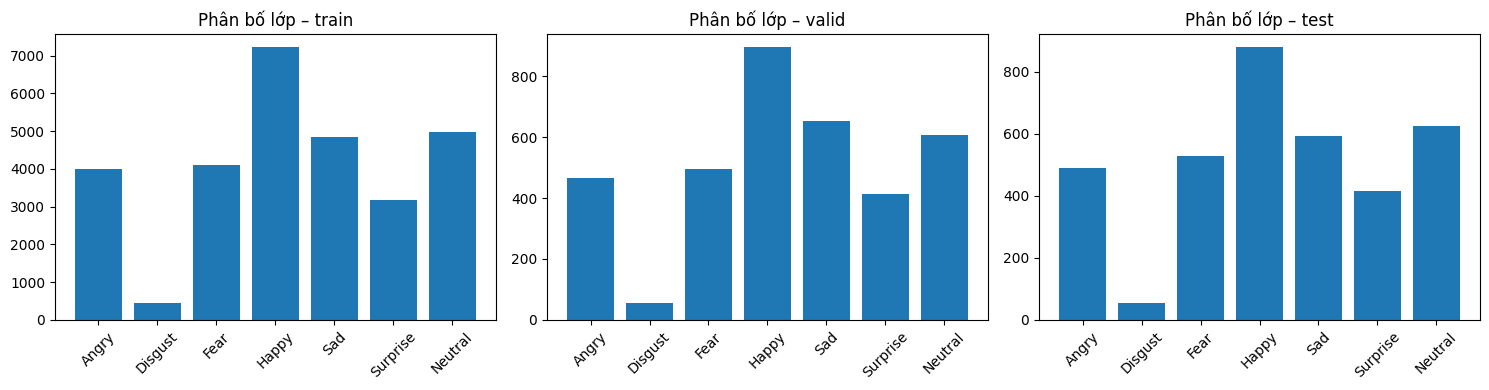

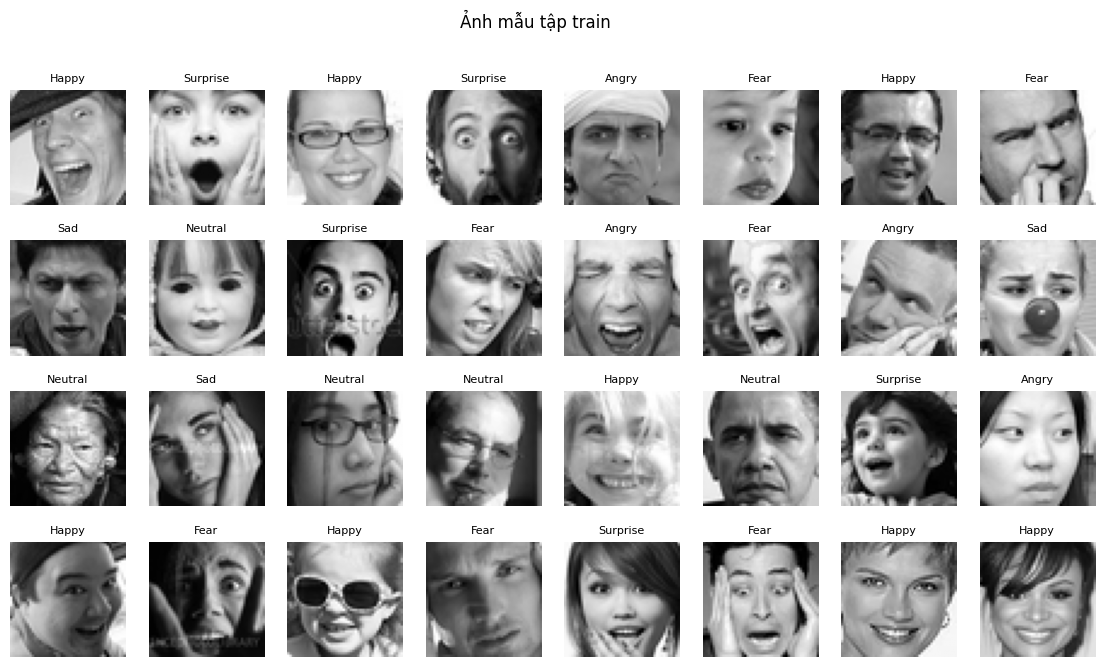

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15,4))
for a,(k,(x,y)) in zip(ax, DATA.items()):
    a.bar(CLASSES, np.bincount(y, minlength=7)); a.set_title(f'Phân bố lớp – {k}'); a.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

x,y = DATA['train']; idx = np.random.RandomState(0).choice(len(x), 32, replace=False)
fig, axs = plt.subplots(4, 8, figsize=(14,7.5))
for a,i in zip(axs.ravel(), idx):
    a.imshow(x[i], cmap='gray'); a.set_title(CLASSES[y[i]], fontsize=8); a.axis('off')
plt.suptitle('Ảnh mẫu tập train'); plt.show()

## 1.6 Kiểm tra augmentation

torch.Size([32, 1, 48, 48]) tensor([4, 6, 4, 3, 6, 3, 3, 4]) mean/std train = 0.508 0.255


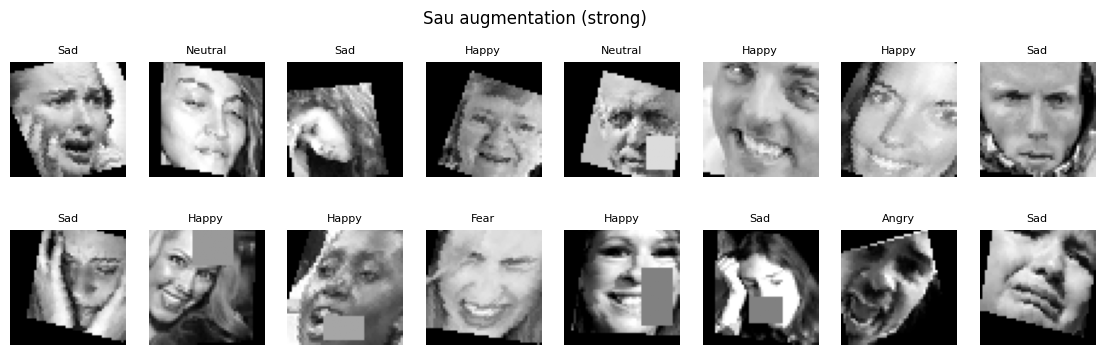

In [7]:
loaders, counts, (mean, std) = make_loaders(32, 'strong')
xb, yb = next(iter(loaders['train']))
print(xb.shape, yb[:8], 'mean/std train =', round(mean,3), round(std,3))
fig, axs = plt.subplots(2, 8, figsize=(14,4))
for a, im, l in zip(axs.ravel(), xb[:16], yb[:16]): a.imshow(im[0], cmap='gray'); a.set_title(CLASSES[int(l)], fontsize=8); a.axis('off')
plt.suptitle('Sau augmentation (strong)'); plt.show()